### ***EDA***

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from models import AlcoholLogisticModel

Pregunta de negocio: ¿En qué franja horaria se producen los accidentes con mayor gravedad (ingreso superior a 24 horas o fallecidos) y qué condiciones (estado meteorológico, tipo de accidente, etc.) pueden influir en ello?”

**DESCRIPCIÓN DE LOS DATOS**

In [6]:
db = pd.read_csv("2024_Accidentalidad.csv",sep=";")

In [7]:
db.shape #Vemos el tamaño del dataset (filas, columnas)

(49340, 19)

In [8]:
db.head(10)#Primera vista del dataset

,num_expediente,fecha,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,cod_lesividad,lesividad,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,positiva_droga
0,2023S040280,04/01/2024,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión fronto-lateral,Lluvia débil,Motocicleta > 125cc,Conductor,De 55 a 59 años,Hombre,2.0,Ingreso inferior o igual a 24 horas,444913.0,4481427.0,N,NaN
1,2023S040280,04/01/2024,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión fronto-lateral,Lluvia débil,Turismo,Conductor,De 55 a 59 años,Mujer,14.0,Sin asistencia sanitaria,444913.0,4481427.0,N,NaN
2,2023S040309,15/02/2024,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión fronto-lateral,Lluvia débil,Bicicleta,Conductor,De 25 a 29 años,Hombre,7.0,Asistencia sanitaria sólo en el lugar del acci...,440123.0,4475170.0,N,NaN
3,2023S040309,15/02/2024,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión fronto-lateral,Lluvia débil,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,Hombre,14.0,Sin asistencia sanitaria,440123.0,4475170.0,N,NaN
4,2023S040310,18/02/2024,10:40:00,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión lateral,Despejado,Turismo,Conductor,De 25 a 29 años,Hombre,NaN,NaN,440137.0,4475721.0,N,NaN
5,2023S040310,18/02/2024,10:40:00,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión lateral,Despejado,Turismo,Conductor,De 55 a 59 años,Hombre,NaN,NaN,440137.0,4475721.0,N,NaN
6,2023S040312,25/02/2024,17:20:00,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión lateral,Despejado,Camión rígido,Conductor,De 25 a 29 años,Hombre,14.0,Sin asistencia sanitaria,440709.0,4480102.0,N,NaN
7,2023S040312,25/02/2024,17:20:00,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión lateral,Despejado,Maquinaria de obras,Conductor,De 50 a 54 años,Hombre,14.0,Sin asistencia sanitaria,440709.0,4480102.0,N,NaN
8,2023S040316,07/03/2024,14:25:00,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Furgoneta,Conductor,De 60 a 64 años,Hombre,NaN,NaN,433983.0,4468473.0,N,NaN
9,2023S040316,07/03/2024,14:25:00,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Turismo,Conductor,De 25 a 29 años,Hombre,NaN,NaN,433983.0,4468473.0,N,NaN


In [9]:
num_duplicados = db.duplicated().sum()

In [10]:
print(num_duplicados)

2053


In [11]:
db.drop_duplicates(inplace=True) #Vemos que hay 2053 registros duplicados. Procedemos a eliminarlos.

In [12]:
db.shape

(47287, 19)

In [13]:
db.info()#Vemos el tipo de datos que hay.

<class 'pandas.core.frame.DataFrame'>
Index: 47287 entries, 0 to 49339
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   num_expediente        47287 non-null  object 
 1   fecha                 47287 non-null  object 
 2   hora                  47287 non-null  object 
 3   localizacion          47287 non-null  object 
 4   numero                47287 non-null  object 
 5   cod_distrito          47287 non-null  int64  
 6   distrito              47287 non-null  object 
 7   tipo_accidente        47282 non-null  object 
 8   estado_meteorológico  41708 non-null  object 
 9   tipo_vehiculo         46898 non-null  object 
 10  tipo_persona          47287 non-null  object 
 11  rango_edad            47287 non-null  object 
 12  sexo                  47287 non-null  object 
 13  cod_lesividad         26954 non-null  float64
 14  lesividad             26954 non-null  object 
 15  coordenada_x_utm      47

In [14]:
#Vemos que hay muchos datos nulos en las variables referentes a la lesividad y en el positivo de droga (en este último los valores son o Nulos o 1).

In [15]:
db.columns#Vemos el nombre de las columnas que hay.

Index(['num_expediente', 'fecha', 'hora', 'localizacion', 'numero',
       'cod_distrito', 'distrito', 'tipo_accidente', 'estado_meteorológico',
       'tipo_vehiculo', 'tipo_persona', 'rango_edad', 'sexo', 'cod_lesividad',
       'lesividad', 'coordenada_x_utm', 'coordenada_y_utm', 'positiva_alcohol',
       'positiva_droga'],
      dtype='object')

**PREPARACIÓN Y LIMPIEZA DE LOS DATOS**

In [17]:
#El dato de positividad droga podría ser relevante para la respuesta de negocio pero tenemos únicamente 203 registros de 49173 y el resto son nulos. 
#Además tampoco se especifica si uno es positivo o negativo en drogas por lo que procedemos a eliminar dicha columna.

In [18]:
db.drop(labels='positiva_droga', axis = 1, inplace = True)

In [19]:
db.drop(labels='num_expediente', axis = 1, inplace = True) #Eliminamos número de expediente ya que no es un dato que vaya a ser relevante para 
#el análisis

In [20]:
db.columns

Index(['fecha', 'hora', 'localizacion', 'numero', 'cod_distrito', 'distrito',
       'tipo_accidente', 'estado_meteorológico', 'tipo_vehiculo',
       'tipo_persona', 'rango_edad', 'sexo', 'cod_lesividad', 'lesividad',
       'coordenada_x_utm', 'coordenada_y_utm', 'positiva_alcohol'],
      dtype='object')

In [21]:
db.isnull().sum()#Tras la eliminación de lo anterior, vemos cuantos datos nulos hay todavía.

fecha                       0
hora                        0
localizacion                0
numero                      0
cod_distrito                0
distrito                    0
tipo_accidente              5
estado_meteorológico     5579
tipo_vehiculo             389
tipo_persona                0
rango_edad                  0
sexo                        0
cod_lesividad           20333
lesividad               20333
coordenada_x_utm            6
coordenada_y_utm            6
positiva_alcohol          167
dtype: int64

In [22]:
#De la misma manera, tipo de accidente, tipo de vehiculo, coordenada y, coordenada x y positiva en alcohol son pocos datos nulos. Teniendo en cuenta la cantidad de registros
#que tenemos, procedemos a eliminar sus valores nulos.
db = db[~db["tipo_accidente"].isnull()]
db = db[~db["tipo_vehiculo"].isnull()]
db = db[~db["coordenada_x_utm"].isnull()]
db = db[~db["coordenada_y_utm"].isnull()]
db = db[~db["positiva_alcohol"].isnull()]

In [23]:
db.isnull().sum()

fecha                       0
hora                        0
localizacion                0
numero                      0
cod_distrito                0
distrito                    0
tipo_accidente              0
estado_meteorológico     5515
tipo_vehiculo               0
tipo_persona                0
rango_edad                  0
sexo                        0
cod_lesividad           19877
lesividad               19877
coordenada_x_utm            0
coordenada_y_utm            0
positiva_alcohol            0
dtype: int64

In [24]:
colisiones_dobles = ['Colisión frontal', 'Colisión fronto-lateral', 'Colisión lateral']#En los datos pone que colisiones dobles es igual a
#frontal, lateral y fronto lateral

In [25]:
db['tipo_accidente'] = db['tipo_accidente'].replace(colisiones_dobles, 'Colisión doble')#Reemplazamos por 'Colisión dobles'

In [26]:
db['cod_lesividad'] = db['cod_lesividad'].fillna(14.0)

In [27]:
db['lesividad'] = db['lesividad'].fillna("Sin asistencia sanitaria")#Sustituimos los Na por 14. Sin asistencia sanitaria

In [28]:
db.isnull().sum()

fecha                      0
hora                       0
localizacion               0
numero                     0
cod_distrito               0
distrito                   0
tipo_accidente             0
estado_meteorológico    5515
tipo_vehiculo              0
tipo_persona               0
rango_edad                 0
sexo                       0
cod_lesividad              0
lesividad                  0
coordenada_x_utm           0
coordenada_y_utm           0
positiva_alcohol           0
dtype: int64

In [29]:
meteorologico_moda = db.estado_meteorológico.mode()[0]#Rellenamos los datos vacíos de estado meteorológico sacando la moda e imputándola.

In [30]:
meteorologico_moda

'Despejado'

Al ser pocos registros, para no eliminarlos sacamos la moda del estado meteorológico y lo imputamos a la variable estado meteorológico

In [32]:
db["estado_meteorológico"] = db["estado_meteorológico"].fillna(meteorologico_moda)

In [33]:
db.isnull().sum()#Vemos que ya no tenemos valores nulos.

fecha                   0
hora                    0
localizacion            0
numero                  0
cod_distrito            0
distrito                0
tipo_accidente          0
estado_meteorológico    0
tipo_vehiculo           0
tipo_persona            0
rango_edad              0
sexo                    0
cod_lesividad           0
lesividad               0
coordenada_x_utm        0
coordenada_y_utm        0
positiva_alcohol        0
dtype: int64

In [34]:
db.dtypes #Vemos el tipo de datos de cada columna

fecha                    object
hora                     object
localizacion             object
numero                   object
cod_distrito              int64
distrito                 object
tipo_accidente           object
estado_meteorológico     object
tipo_vehiculo            object
tipo_persona             object
rango_edad               object
sexo                     object
cod_lesividad           float64
lesividad                object
coordenada_x_utm        float64
coordenada_y_utm        float64
positiva_alcohol         object
dtype: object

In [35]:
db['fecha'] = pd.to_datetime(db['fecha'], format="%d/%m/%Y")
db['mes'] = db['fecha'].dt.month
db.drop(labels='fecha', axis = 1, inplace = True)
#PONEMOS LA FECHA Y HORA EN EL FORMATO CORRECTO PARA QUE NO SEA TIPO OBJECT Y SEA TIPO DATATIME. DE ESA MANERA, LOGRAMOS SIN PROBLEMA (EN EL CASO DE LA FECHA) 
#CREAR UNA COLUMNA DE MES Y ELIMINAMOS LA COLUMNA FECHA. (NO CREAMOS UNA DE AÑO PORQUE EL AÑO SIEMPRE ES 2024)

In [36]:
db['hora'] = pd.to_datetime(db['hora'], format="%H:%M:%S").dt.hour
#Redondeamos la hora para que nos ponga si el accidente fue a las 14,15,16 y asi nos queda más limpia la columna.

In [37]:
db.dtypes #Confirmamos la modificación (ya está la hora y el mes modificados).

hora                      int32
localizacion             object
numero                   object
cod_distrito              int64
distrito                 object
tipo_accidente           object
estado_meteorológico     object
tipo_vehiculo            object
tipo_persona             object
rango_edad               object
sexo                     object
cod_lesividad           float64
lesividad                object
coordenada_x_utm        float64
coordenada_y_utm        float64
positiva_alcohol         object
mes                       int32
dtype: object

**ANALISIS UNIVARIANTE**

In [39]:
db.tipo_accidente.value_counts(normalize=True)

tipo_accidente
Colisión doble                  0.458145
Alcance                         0.250337
Choque contra obstáculo fijo    0.100109
Atropello a persona             0.062092
Caída                           0.056384
Colisión múltiple               0.046655
Otro                            0.016314
Solo salida de la vía           0.005067
Vuelco                          0.003378
Atropello a animal              0.001518
Name: proportion, dtype: float64

La colisión doble y el alcance se llevan la palma en porcentaje de tipo de accidente.

<Axes: ylabel='estado_meteorológico'>

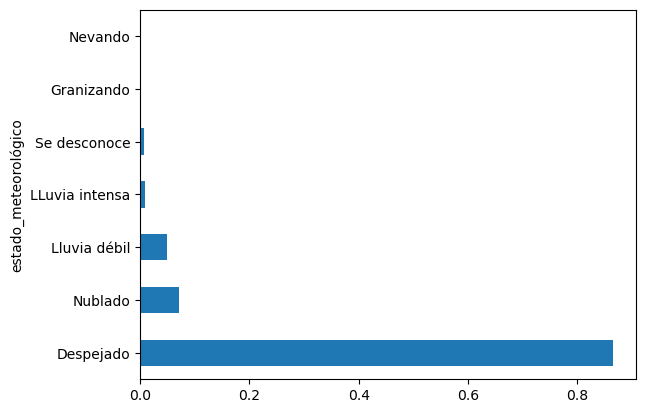

In [41]:
db.estado_meteorológico.value_counts(normalize=True).plot.barh()

Llama la atención que el tiempo sea despejado ya que la mayoría de accidentes se dan en días con mala climatología: primero porque se conduce
peor con mala climatología y segundo porque en días por ejemplo lluviosos suele ser uno de los transportes más usados.

In [43]:
db.tipo_vehiculo.value_counts(normalize=True)

tipo_vehiculo
Turismo                              0.681883
Motocicleta hasta 125cc              0.069897
Furgoneta                            0.068058
Motocicleta > 125cc                  0.038423
Autobús                              0.031452
Camión rígido                        0.024418
Todo terreno                         0.017447
Bicicleta                            0.017319
VMU eléctrico                        0.016421
Ciclomotor                           0.009942
Bicicleta EPAC (pedaleo asistido)    0.005559
Tractocamión                         0.004512
Maquinaria de obras                  0.003827
Otros vehículos con motor            0.003485
Vehículo articulado                  0.001796
Autobús articulado                   0.001604
Cuadriciclo ligero                   0.000898
Sin especificar                      0.000706
Autobus EMT                          0.000556
Cuadriciclo no ligero                0.000406
Ciclo                                0.000363
Autocaravana        

Los turismos fueron por una amplia mayoria los más implicados en los accidentes.

<Axes: ylabel='count'>

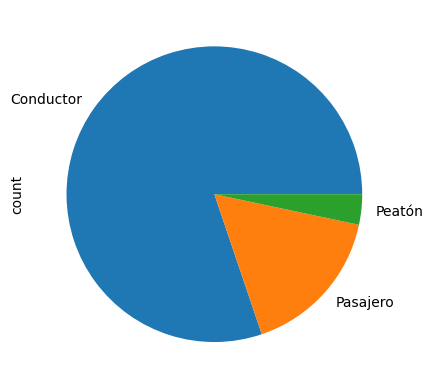

In [45]:
db.tipo_persona.value_counts().plot.pie()

Tiene sentido que la mayoría de implicados sean conductor pasajeros al ser el turismo el mayor implicado.

<Axes: ylabel='count'>

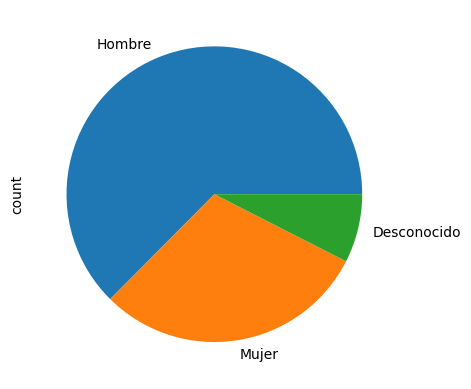

In [47]:
db.sexo.value_counts().plot.pie()

Los hombres se llevan la palma, también vemos una pequeña proporción de datos desconocidos pero teniendo en cuenta la mayoría que tenemos de hombres
no parece relevante.

In [49]:
db.distrito.value_counts(normalize=True)

distrito
PUENTE DE VALLECAS     0.080203
CHAMARTÍN              0.072976
CARABANCHEL            0.070346
SALAMANCA              0.067032
CIUDAD LINEAL          0.061344
CENTRO                 0.057645
ARGANZUELA             0.054780
RETIRO                 0.051957
FUENCARRAL-EL PARDO    0.050332
MONCLOA-ARAVACA        0.048451
TETUÁN                 0.047360
LATINA                 0.046633
SAN BLAS-CANILLEJAS    0.046227
CHAMBERÍ               0.044688
USERA                  0.041865
HORTALEZA              0.036477
VILLAVERDE             0.033655
MORATALAZ              0.028587
VILLA DE VALLECAS      0.024589
VICÁLVARO              0.017832
BARAJAS                0.017020
Name: proportion, dtype: float64

Vemos que están muy repartidos los accidentes en función del distrito por lo que no podemos sacar una conclusión clara.

In [51]:
db.rango_edad.value_counts(normalize=True)

rango_edad
De 45 a 49 años    0.105583
De 30 a 34 años    0.101777
De 25 a 29 años    0.100387
De 40 a 44 años    0.099232
De 35 a 39 años    0.096859
De 50 a 54 años    0.095469
Desconocido        0.076504
De 55 a 59 años    0.073745
De 21 a 24 años    0.067930
De 60 a 64 años    0.051594
De 18 a 20 años    0.031688
Más de 74 años     0.025123
De 65 a 69 años    0.024824
De 70 a 74 años    0.015480
De 15 a 17 años    0.009451
Menor de 5 años    0.009173
De 10 a 14 años    0.008938
De 6 a 9 años      0.006243
Name: proportion, dtype: float64

Lo mismo nos pasa con la edad, aunque nos cuadran los datos ya que la persona más implicada es el conductor y la mayoría de datos están agrupados
en la mayoría de edad.

In [53]:
db.lesividad.value_counts(normalize=True)

lesividad
Sin asistencia sanitaria                                     0.763155
Asistencia sanitaria sólo en el lugar del accidente          0.121854
Ingreso inferior o igual a 24 horas                          0.039471
Atención en urgencias sin posterior ingreso                  0.028288
Asistencia sanitaria inmediata en centro de salud o mutua    0.023498
Ingreso superior a 24 horas                                  0.011974
Asistencia sanitaria ambulatoria con posterioridad           0.011097
Fallecido 24 horas                                           0.000620
Se desconoce                                                 0.000043
Name: proportion, dtype: float64

Vemos que la gravedad de los accidentes por fortuna nos es elevada.

In [55]:
db.mes.value_counts()

mes
10    4412
12    4366
11    4293
5     4222
4     4107
6     4022
9     3967
2     3799
3     3783
1     3645
7     3602
8     2551
Name: count, dtype: int64

Aquí podemos ver que los accidentes como es lógico en Madrid bajan en Verano.

In [57]:
db.hora.value_counts(normalize=True)

hora
19    0.072142
18    0.071051
14    0.069020
15    0.067374
17    0.064166
20    0.061964
13    0.060489
16    0.055956
12    0.053283
9     0.053112
21    0.045714
11    0.044602
8     0.044538
10    0.039984
22    0.035750
23    0.028587
7     0.026663
0     0.023841
1     0.020291
6     0.017212
2     0.013727
5     0.011311
3     0.010669
4     0.008553
Name: proportion, dtype: float64

In [58]:
db.hora.value_counts()

hora
19    3374
18    3323
14    3228
15    3151
17    3001
20    2898
13    2829
16    2617
12    2492
9     2484
21    2138
11    2086
8     2083
10    1870
22    1672
23    1337
7     1247
0     1115
1      949
6      805
2      642
5      529
3      499
4      400
Name: count, dtype: int64

Aquí lo que se puede apreciar es que de madrugada no hay accidentes.

In [60]:
db.positiva_alcohol.value_counts(normalize=True)

positiva_alcohol
N    0.969381
S    0.030619
Name: proportion, dtype: float64

Vemos que el alcohol no influye en los accidentes ya que la mayoria de los controles salieron negativos. Lo cual nos cuadra con las horas ya que normalmente
el alcohol se suele ingerir durante la noche/madrugada.

De lo que hemos visto es que en los accidentes por el momento la mayoría de datos se concentran si hacía buen tiempo, los implicados eran conductores, hombres, en un turismo, en los meses que no son de verano y en horas 'laborables'.

**ANALISIS BIVARIANTE**

A la hora de utilizar variables categóricas para luego poder trabajar con ellas (la idea es codificarlas), vemos aquellas que son object y que sería necesario intentar variar su valor para analizarlas. Las variables que podrían ser modificadas son: 
Tipo accidente, Estado meteorológico, Tipo de vehículo, Tipo de persona, Sexo, Positiva en alcohol.
A priori estas serían las variables categóricas que tendrían un impacto directo en los accidentes. Vamos a utlizar label para etiquetar estas variables categóricas y poder realizar una matriz de correlación para ver que influye más directamente en los accidentes y en la gravedad de los mismos.


In [64]:
columnas_label = ['tipo_accidente', 'estado_meteorológico', 'tipo_vehiculo', 'tipo_persona', 'sexo', 'positiva_alcohol']#Hemos metido positivo en alcohol
#para recopilar posibles relaciones de cara al modelo posterior.

In [65]:
etiquetas ={}#Diccionario donde se guardarán las etiquetas

In [66]:
for col in columnas_label:
    le = LabelEncoder()                                   
    db['cod_' + col] = le.fit_transform(db[col])#Con esto logramos que se cree una columna (así tenemos para futuros el laber y el valor categórico).   
    etiquetas[col] = le 

In [67]:
db.head(5)

,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,...,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,mes,cod_tipo_accidente,cod_estado_meteorológico,cod_tipo_vehiculo,cod_tipo_persona,cod_sexo,cod_positiva_alcohol
0,14,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión doble,Lluvia débil,Motocicleta > 125cc,Conductor,De 55 a 59 años,...,444913.0,4481427.0,N,1,5,3,19,0,1,0
1,14,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión doble,Lluvia débil,Turismo,Conductor,De 55 a 59 años,...,444913.0,4481427.0,N,1,5,3,29,0,2,0
2,14,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión doble,Lluvia débil,Bicicleta,Conductor,De 25 a 29 años,...,440123.0,4475170.0,N,2,5,3,5,0,1,0
3,14,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión doble,Lluvia débil,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,...,440123.0,4475170.0,N,2,5,3,20,0,1,0
4,10,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión doble,Despejado,Turismo,Conductor,De 25 a 29 años,...,440137.0,4475721.0,N,2,5,0,29,0,1,0


In [68]:
selección_datos_correlación = ['hora', 'cod_distrito','mes', 'cod_tipo_accidente','cod_estado_meteorológico','cod_tipo_vehiculo','cod_tipo_persona','cod_sexo','cod_positiva_alcohol']

In [69]:
matriz_corr = db[selección_datos_correlación].corr()

In [70]:
matriz_corr #seleccionamos datos para etiquetar y creamos una matriz de correlación.

,hora,cod_distrito,mes,cod_tipo_accidente,cod_estado_meteorológico,cod_tipo_vehiculo,cod_tipo_persona,cod_sexo,cod_positiva_alcohol
hora,1.000000,0.018270,-0.011204,-0.039768,0.001704,-0.000163,0.019259,0.049142,-0.080207
cod_distrito,0.018270,1.000000,0.000721,0.045331,-0.011816,0.071550,0.009481,-0.012413,0.025226
mes,-0.011204,0.000721,1.000000,0.005267,-0.043716,-0.004836,0.010570,-0.000606,0.001595
cod_tipo_accidente,-0.039768,0.045331,0.005267,1.000000,-0.019375,-0.021142,-0.085716,-0.072323,0.022360
cod_estado_meteorológico,0.001704,-0.011816,-0.043716,-0.019375,1.000000,-0.002132,0.003042,0.013110,-0.012121
cod_tipo_vehiculo,-0.000163,0.071550,-0.004836,-0.021142,-0.002132,1.000000,0.034465,0.101416,0.033119
cod_tipo_persona,0.019259,0.009481,0.010570,-0.085716,0.003042,0.034465,1.000000,0.285146,-0.069103
cod_sexo,0.049142,-0.012413,-0.000606,-0.072323,0.013110,0.101416,0.285146,1.000000,-0.021652
cod_positiva_alcohol,-0.080207,0.025226,0.001595,0.022360,-0.012121,0.033119,-0.069103,-0.021652,1.000000


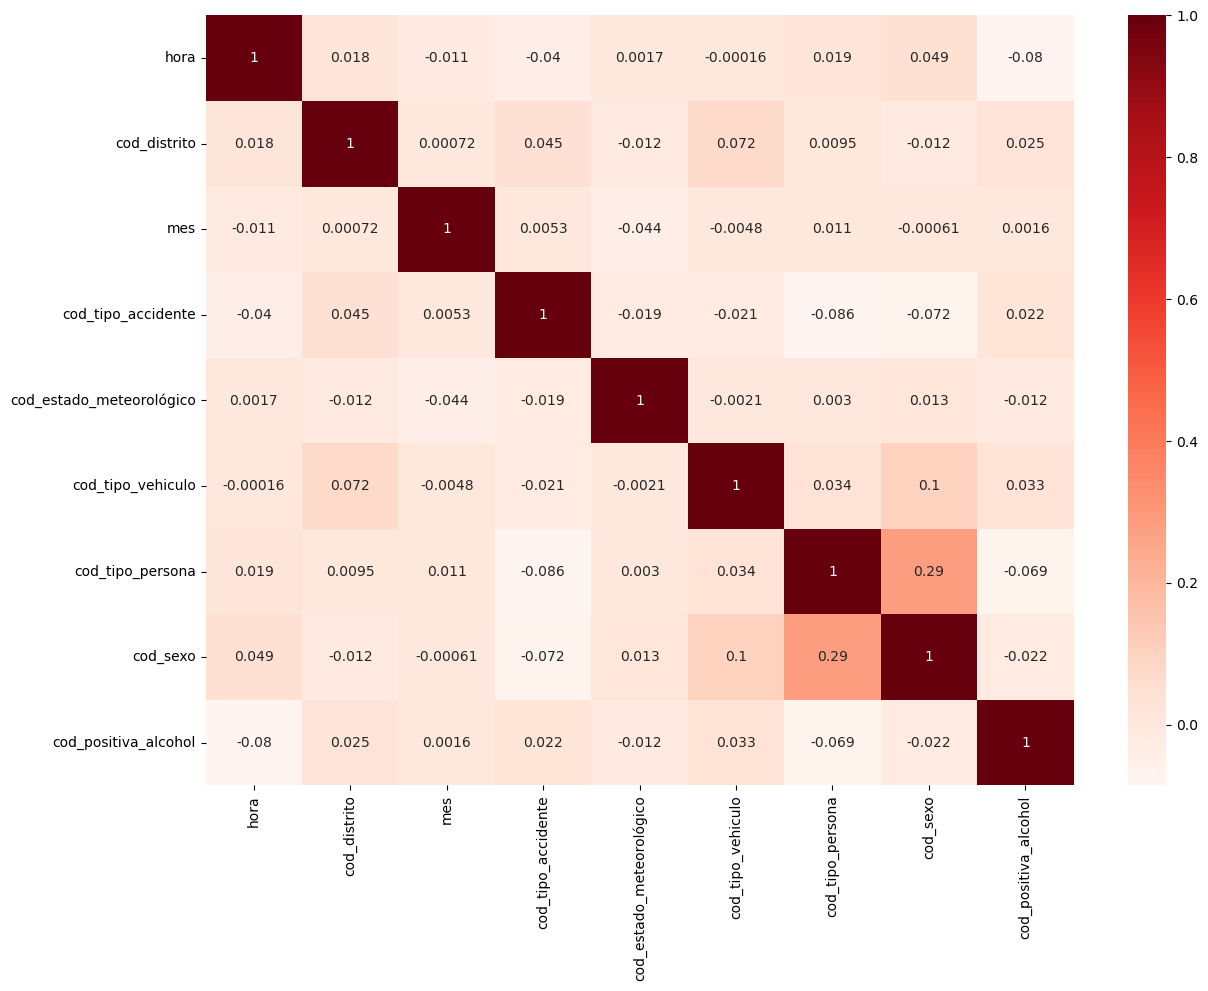

In [71]:
plt.figure(figsize=(14, 10))
sns.heatmap(matriz_corr, annot=True, cmap = "Reds")
plt.show()

Haciendo la matriz de correlación no vemos a priori ningún tipo de relación directa. Lo más llamativo es que de una manera muy suave existe una 
mínima relación entre el sexo y el tipo de persona. 
Dado que no sacamos directamente ninguna relación directa, vamos a intentar con gráficos responder a nuestra pregutna de negocio:
¿En qué franja horaria se producen los accidentes con mayor gravedad (ingreso superior a 24 horas o fallecidos) y qué condiciones (estado meteorológico, tipo de accidente, etc.) pueden influir en ello?”

Primero vamos a ver en que franja horaria se producen los accidentes con ingreso superior a 24 o fallecidos

In [74]:
accidentes_graves = db[(db['lesividad'] == 'Fallecido 24 horas') |(db['lesividad'] == 'Ingreso superior a 24 horas')] #filtramos los valores del dataset que tengan estos campos

In [75]:
accidentes_graves_por_hora = accidentes_graves['hora'].value_counts()

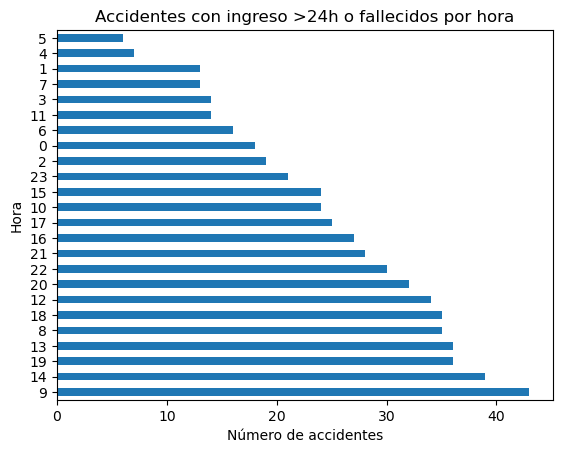

In [76]:
accidentes_graves_por_hora.plot.barh()
plt.title('Accidentes con ingreso >24h o fallecidos por hora')
plt.xlabel('Número de accidentes')
plt.ylabel('Hora')
plt.show()

Vemos que hay tres tramos diferenciados: 8-9, 18-22 y 12-14. Parecen ser los horarios en los que uno se desplaza para ir al trabajo, para volver del trabajo y el tramo intermedio tendría sentido en el caso de ir a comer o quedar para comer. Vamos a ver los todos los accidentes por hora:

In [78]:
accidentes_totales_por_hora = db['hora'].value_counts()

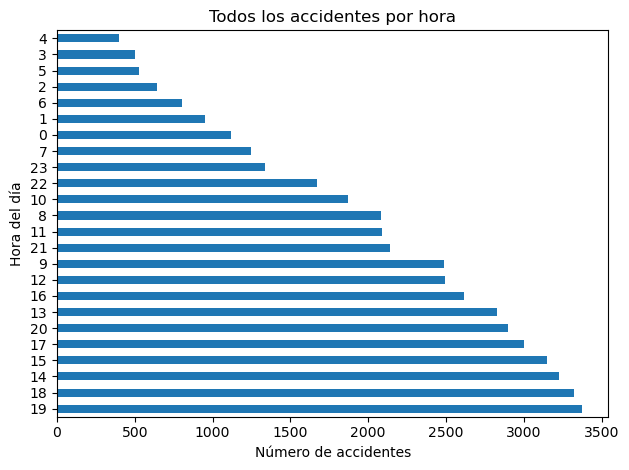

In [79]:
accidentes_totales_por_hora.plot.barh()
plt.title('Todos los accidentes por hora')
plt.xlabel('Número de accidentes')
plt.ylabel('Hora del día')
plt.tight_layout()
plt.show()

Aquí podemos ver que la gran mayoría de los accidentes se producen entre las 14 y las 20 horas por lo que podemos determinar que este tramo de accidentes es el más peligroso.

Teniendo en cuenta los datos (de 14-20 la mayoría de los accidentes y por la tarde (hospitalización mayor de 24 horas o fallecidos) los más graves se producen entre las 18-22 podemos defiinir como tramo negro 17 - 21 para tener más datos de muestra).

In [82]:
tramo_negro = db[(db['hora'] >= 17) & (db['hora'] <= 21)]#Definimos nuestro tramo negro

In [83]:
pivot_alcohol_sexo = pd.pivot_table(data= tramo_negro, index='positiva_alcohol', columns='sexo', values='hora', aggfunc='count')#Ulizamos aggfunc para que cuente valores y no haga media.

In [84]:
pivot_alcohol_sexo 

sexo,Desconocido,Hombre,Mujer
positiva_alcohol,,,
N,1039.0,8677.0,4604.0
S,NaN,358.0,56.0


Vemos en la tabla pivotante que la mayoria de accidentes en el tramo negro dieron negativo en alcohol y en la gran mayoría fueron hombres.

Ahora vamos a ver en dicho tramo negro, donde se produjeron los accidentes.

In [91]:
tramo_negro = db[(db['hora'] >= 17) & (db['hora'] <= 21)]#Definimos nuestro tramo negro

In [93]:
accidentes_por_distrito = tramo_negro['distrito'].value_counts()

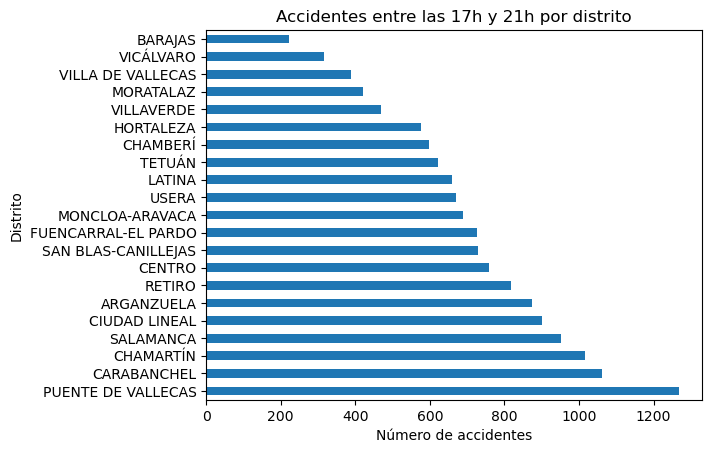

In [97]:
accidentes_por_distrito.plot.barh()
plt.title('Accidentes entre las 17h y 21h por distrito')
plt.xlabel('Número de accidentes')
plt.ylabel('Distrito')
plt.show()

Tanto Carabanchel, como puente de vallecas son barrio de retorno después de trabajar aunque no terminan de cuadrar los accidentes en chamartín y salamanca.
Vamos a ver si por la localización podemos sacar alguna conclusión.

In [100]:
accidentes_por_localización = tramo_negro['localizacion'].value_counts()

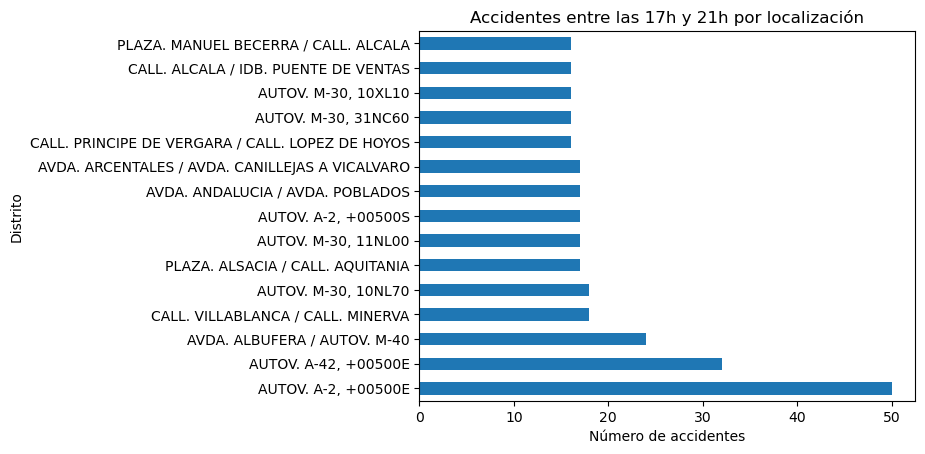

In [102]:
accidentes_por_localización.head(15).plot.barh()
plt.title('Accidentes entre las 17h y 21h por localización')
plt.xlabel('Número de accidentes')
plt.ylabel('Distrito')
plt.show()

Aquí vemos que la mayoría de los accidentes en los puntos negros son en carretera, lo cual nos da a entender que son de retorno a casa del trabajo dadas las horas que son.
Llama la atención el punto de la calle villablanca/minerva ya que no es una carretera sino un cruce de calles.

De cara a mirar el perfil de las personas que tienen accidentes, vamos a ver si hay algún rango de edad dominante.

In [106]:
accidentes_por_edad = tramo_negro['rango_edad'].value_counts()

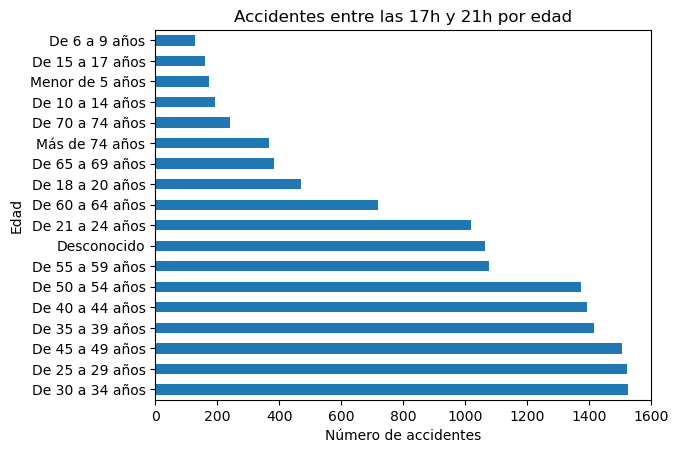

In [108]:
accidentes_por_edad.plot.barh()
plt.title('Accidentes entre las 17h y 21h por edad')
plt.xlabel('Número de accidentes')
plt.ylabel('Edad')
plt.show()

Vemos que los accidentes se producen en el tramo de edad 25 - 55. Tiene sentido ya que coge la gran mayoría de vida laboral que suele tener una persona. Teniendo en cuenta que la mayoría de implicados eran conductores tiene sentido que sean mayores de edad y que sean ellos los que conducían. 

In [110]:
accidentes_por_mes = db['mes'].value_counts()

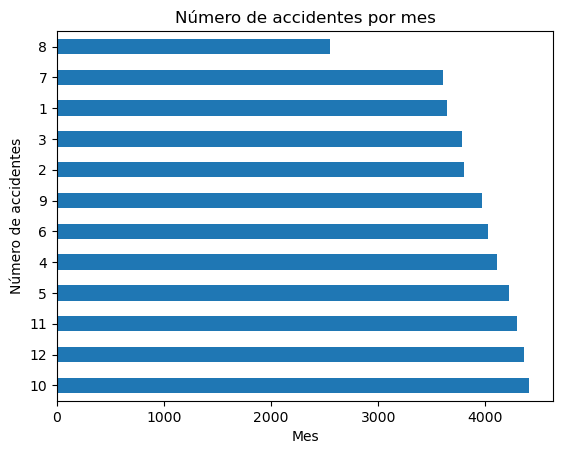

In [111]:
accidentes_por_mes.plot.barh()
plt.title('Número de accidentes por mes')
plt.xlabel('Mes')
plt.ylabel('Número de accidentes')
plt.show()

Por último, observamos que los meses que menos gente hay en Madrid es cuando menos accidentes se producen.

A continuación vamos a coger los datos totales de tipo de accidente

In [116]:
db['tipo_accidente'].value_counts()

tipo_accidente
Colisión doble                  21427
Alcance                         11708
Choque contra obstáculo fijo     4682
Atropello a persona              2904
Caída                            2637
Colisión múltiple                2182
Otro                              763
Solo salida de la vía             237
Vuelco                            158
Atropello a animal                 71
Name: count, dtype: int64

In [118]:
accidentes_por_tipoaccidente = tramo_negro['tipo_accidente'].value_counts()

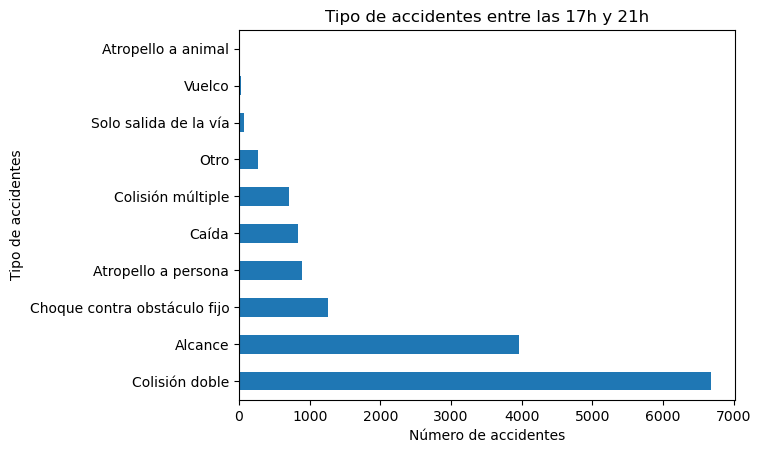

In [120]:
accidentes_por_tipoaccidente.plot.barh()
plt.title('Tipo de accidentes entre las 17h y 21h')
plt.xlabel('Número de accidentes')
plt.ylabel('Tipo de accidentes')
plt.show()

Nos sigue cuadrando que en el tramo negro los accidentes son entre coches o en los que los coches están implicados (de ahí que la mayoría de accidentes sea de coches.)

A priori las conclusiones están bastante claras pero vamos a solucionar alguna pregunta adicional de las propuestas ya que pueden ser interesantes:

**¿Se observa alguna relación entre el estado meteorológico y la lesividad de los accidentes?**

In [126]:
db.groupby('lesividad')['estado_meteorológico'].value_counts()

lesividad                                                  estado_meteorológico
Asistencia sanitaria ambulatoria con posterioridad         Despejado                 430
                                                           Nublado                    37
                                                           Lluvia débil               31
                                                           LLuvia intensa             15
                                                           Se desconoce                6
Asistencia sanitaria inmediata en centro de salud o mutua  Despejado                 922
                                                           Nublado                    81
                                                           Lluvia débil               72
                                                           LLuvia intensa             19
                                                           Se desconoce                5
Asistencia sanitaria sólo en e

Vemos que en todos los tipos de accidentes siempre la mayoria fueron estando el día despejado por lo que el clima no influyó en la lesividad.

**CONCLUSIONES**

Hemos visto en el análisis que el espectro más grande de accidentes se daban por la tarde pero que también a las 9 de la mañana era una hora complicada.
La mayoría de veces los accidentes con ingreso más alto fueron por la tarde aunque entre las 8 y las 9 también se dieron. Muchos de ellos se dieron en carretera y el alcohol o la edad no fueron determinantes.
De cara a lanzar una campaña, me centraría en insistir en que el desplazamiento hacia o desde el trabajo es muy peligroso en horas puntas y que la mayoría de los accidentes se dan por colisiones entre coches (probablemente distracciones). Sería un buen dato de hecho lograr saber cual fue la causa de la distracción (encender un cigarro, hablar por el móvil, etc.)

### ***MODELO DE REGRESIÓN LOGÍSTICA***

Usar la información preprocesada del EDA para entrenar un modelo de Regresión Logística que prediga si un implicado da positivo en alcohol (positiva_alcohol) o no.


**Selección y preparación de las variables**


In [134]:
db.head(10)

,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,...,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,mes,cod_tipo_accidente,cod_estado_meteorológico,cod_tipo_vehiculo,cod_tipo_persona,cod_sexo,cod_positiva_alcohol
0,14,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión doble,Lluvia débil,Motocicleta > 125cc,Conductor,De 55 a 59 años,...,444913.0,4481427.0,N,1,5,3,19,0,1,0
1,14,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión doble,Lluvia débil,Turismo,Conductor,De 55 a 59 años,...,444913.0,4481427.0,N,1,5,3,29,0,2,0
2,14,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión doble,Lluvia débil,Bicicleta,Conductor,De 25 a 29 años,...,440123.0,4475170.0,N,2,5,3,5,0,1,0
3,14,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión doble,Lluvia débil,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,...,440123.0,4475170.0,N,2,5,3,20,0,1,0
4,10,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión doble,Despejado,Turismo,Conductor,De 25 a 29 años,...,440137.0,4475721.0,N,2,5,0,29,0,1,0
5,10,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión doble,Despejado,Turismo,Conductor,De 55 a 59 años,...,440137.0,4475721.0,N,2,5,0,29,0,1,0
6,17,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión doble,Despejado,Camión rígido,Conductor,De 25 a 29 años,...,440709.0,4480102.0,N,2,5,0,7,0,1,0
7,17,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión doble,Despejado,Maquinaria de obras,Conductor,De 50 a 54 años,...,440709.0,4480102.0,N,2,5,0,16,0,1,0
8,14,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Furgoneta,Conductor,De 60 a 64 años,...,433983.0,4468473.0,N,3,0,3,15,0,1,0
9,14,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Turismo,Conductor,De 25 a 29 años,...,433983.0,4468473.0,N,3,0,3,29,0,1,0


Como hemos visto anteriormente, el alcohol no era determinante en el caso de los accidentes. Pero que factores pueden influir en que el resultado sea positivo o negativo? Vamos a proceder a ver algunas variables relacionadas con el alcohol, para poder establecer en nuestro modelo las incluidas en X.

Como la mayoría de los datos arrojan que casi siempre el resultado de la prueba es negativo. Vamos a crear una variable que contenga 
únicamente los valores del dataframe donde el resultado fue si.

In [138]:
control_positivo = db[(db['positiva_alcohol'] == 'S')]

In [140]:
control_positivo.groupby('estado_meteorológico')['positiva_alcohol'].count()

estado_meteorológico
Despejado         1270
LLuvia intensa       7
Lluvia débil        71
Nublado             74
Se desconoce        10
Name: positiva_alcohol, dtype: int64

Vemos que la mayoría de positivos se dieron con el día despejado por lo que el estado meteorológico es relevante.

In [143]:
control_positivo.groupby('tipo_accidente')['positiva_alcohol'].count()

tipo_accidente
Alcance                         253
Atropello a persona              49
Caída                           114
Choque contra obstáculo fijo    455
Colisión doble                  435
Colisión múltiple                56
Otro                             10
Solo salida de la vía            37
Vuelco                           23
Name: positiva_alcohol, dtype: int64

Aquí vemos tres variables predominantes que nos indican que posiblemente la mayoría de accidentes hayan sido con coches. Si lo verificamos:

In [146]:
control_positivo.groupby('tipo_vehiculo')['positiva_alcohol'].count()

tipo_vehiculo
Autobús                                 2
Autobús articulado                      1
Bicicleta                              16
Bicicleta EPAC (pedaleo asistido)      13
Camión rígido                          12
Ciclomotor                             25
Cuadriciclo ligero                      1
Cuadriciclo no ligero                   1
Furgoneta                             105
Motocicleta > 125cc                    40
Motocicleta hasta 125cc                71
Otros vehículos con motor               4
Sin especificar                         1
Todo terreno                           28
Tractocamión                            1
Turismo                              1062
VMU eléctrico                          49
Name: positiva_alcohol, dtype: int64

Vemos que los turismos fueron los que más positivos dieron por amplia mayoría.

In [149]:
control_positivo.groupby('distrito')['positiva_alcohol'].count()

distrito
ARGANZUELA              43
BARAJAS                 13
CARABANCHEL            152
CENTRO                  57
CHAMARTÍN              101
CHAMBERÍ                62
CIUDAD LINEAL           94
FUENCARRAL-EL PARDO     67
HORTALEZA               58
LATINA                 104
MONCLOA-ARAVACA         45
MORATALAZ               34
PUENTE DE VALLECAS     143
RETIRO                  46
SALAMANCA               70
SAN BLAS-CANILLEJAS     57
TETUÁN                  69
USERA                   74
VICÁLVARO               28
VILLA DE VALLECAS       34
VILLAVERDE              81
Name: positiva_alcohol, dtype: int64

El distrito no nos muestra ninguna tendencia significante.

In [152]:
control_positivo.groupby('tipo_persona')['positiva_alcohol'].count()

tipo_persona
Conductor    1399
Pasajero       10
Peatón         23
Name: positiva_alcohol, dtype: int64

Tiene sentido que el positivo sea del conductor ya que es al que le hacen el control. Quizás más que esto, sería interesante ver el sexo:

In [155]:
control_positivo.groupby('sexo')['positiva_alcohol'].count()

sexo
Hombre    1210
Mujer      222
Name: positiva_alcohol, dtype: int64

Los hombres por goleada.

In [158]:
control_positivo.groupby('rango_edad')['positiva_alcohol'].count()

rango_edad
De 15 a 17 años      5
De 18 a 20 años     51
De 21 a 24 años    147
De 25 a 29 años    199
De 30 a 34 años    177
De 35 a 39 años    162
De 40 a 44 años    151
De 45 a 49 años    176
De 50 a 54 años    144
De 55 a 59 años    113
De 60 a 64 años     61
De 65 a 69 años     27
De 70 a 74 años     11
Menor de 5 años      1
Más de 74 años       7
Name: positiva_alcohol, dtype: int64

Predominan las edades centrales. Aquí además vemos datos que no cuadran como por ejemplo el positivo en alcohol de menos de 5 años. No entraremos
ya que no es una variable que vaya a marcar la predicción.

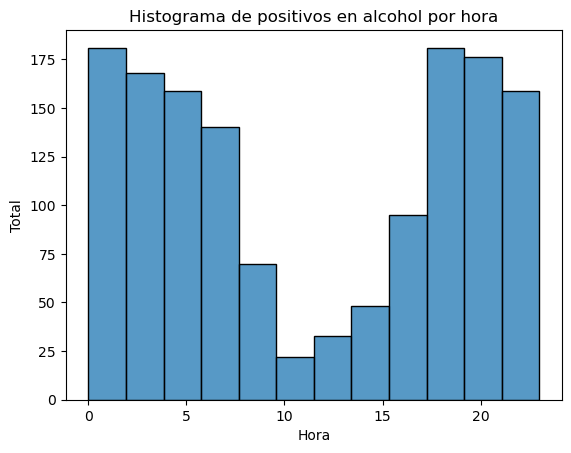

In [161]:
sns.histplot(control_positivo['hora'])
plt.title('Histograma de positivos en alcohol por hora')
plt.xlabel('Hora')
plt.ylabel('Total')
plt.show()

Vemos que los positivos disminuyen en las horas centrales del día.

Procedemos a poner nuestra variable objetivo (y) y a poner las variables que se tendrán en cuenta (X).

In [165]:
y = db["positiva_alcohol"].copy(deep=True)

In [166]:
db[['hora', 'cod_sexo', 'cod_tipo_vehiculo','cod_estado_meteorológico']].head()#ya tenemos las labels hechas en el EDA. las usamos.

,hora,cod_sexo,cod_tipo_vehiculo,cod_estado_meteorológico
0,14,1,19,3
1,14,2,29,3
2,14,1,5,3
3,14,1,20,3
4,10,1,29,0


In [168]:
X = db[['cod_tipo_accidente', 'hora', 'cod_sexo', 'cod_tipo_vehiculo','cod_estado_meteorológico','mes']]

In [171]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [172]:
RegLogAl = AlcoholLogisticModel(X_train, X_test, y_train, y_test)

In [175]:
RegLogAl.fit()

In [176]:
RegLogAl.predict()

array(['N', 'N', 'N', ..., 'N', 'N', 'N'], dtype=object)

Accuracy: 0.9683557836219799


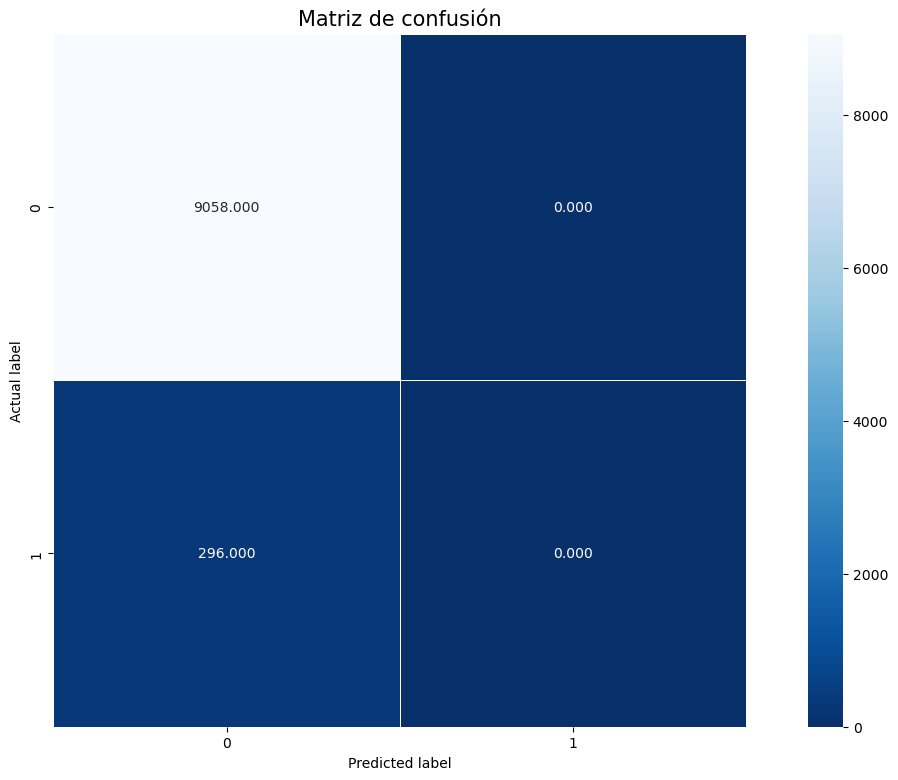

In [177]:
RegLogAl.evaluate()

Vemos que tenemos un accuracy muy elevado pero al hacer la matriz, vemos que hay un problema. Nunca se predicen los valores positivos como positivos ni los negativos como positivos por lo que realmente esto no tendría mucho valor. Está totalmente desbalanceada. Lo adecuado sería probar otro modelo.

In [179]:
RegLogAl.save_model('fernando_modelo.pkl')#se guarda el modelo

In [182]:
RegLogAl.load_model('fernando_modelo.pkl')#se carga el modelo